# El ajuste a prueba de fuga de la tarjeta de puntaje monótona, leído de vuelta sobre las tarjetas de Taiwán

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar el diseño a prueba de fuga del ajuste de C01: qué se separa, para qué puede usarse cada tramo de datos y qué se ajusta solo con el tramo de entrenamiento;
- leer la agrupación monótona que aprendió el ajuste, verificar sus restricciones (tasa de incumplimiento monótona, tramos de al menos el 5% de las tarjetas) sobre los conteos versionados, y ver que todos los conteos vienen de las 16.800 tarjetas de entrenamiento;
- ubicar a mano tarjetas crudas en los tramos aprendidos y recalcular sus puntajes desde la tabla de puntos, exactamente, sin ningún objeto de modelo;
- comparar la tarjeta de puntaje ajustada con una línea base de una sola variable sobre las 9.000 tarjetas reservadas, con las pruebas del motor, y decir qué requiere un reajuste desde el archivo crudo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El mismo caso del cuaderno 01: C01, el archivo de tarjetas de crédito de Taiwán de UCI (Yeh, 2009; CC BY 4.0, clase de licencia `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), 30.000 tarjetas. El ajuste en sí corre en el pipeline (`data-pipeline/pipeline/model/scorecard.py`, con `optbinning`, `statsmodels` y `scikit-learn`) sobre el archivo crudo, que vive fuera del repositorio bajo la raíz de datos. Este cuaderno lee lo que el ajuste versionó y no lo vuelve a correr, así que no necesita ni el archivo crudo ni esas librerías:

- `data/derived/C01/models-taiwan.json`: la división, las variables con sus restricciones, los tramos aprendidos, los coeficientes y la tabla de puntos con los conteos de entrenamiento de cada tramo.
- `data/derived/C01/holdout.json`: la muestra de 50 tarjetas con las entradas crudas, los puntos y el puntaje, y las filas de prueba versionadas de las 9.000 tarjetas reservadas.

La siguiente celda carga ambos archivos.

In [2]:
# Cargar los dos archivos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))

fit = models["fit"]
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
print("semilla del cálculo:", fit["seed"], "| filas en el archivo:", fit["split"]["train"]["n"] + fit["split"]["calibration"]["n"] + fit["split"]["holdout"]["n"])
print("calculado por riskvalidation", models["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)


semilla del cálculo: 42 | filas en el archivo: 30000
calculado por riskvalidation 0.4.3 | instalado 0.8.1


## Método

### Paso 1: la división a prueba de fuga

Las reglas de la investigación para todo ajuste de scoring (la base de investigación del producto, dossier 04, "reglas universales de fuga") dicen que toda transformación se **ajusta solo con el tramo de entrenamiento** (agrupación, WoE, imputación, escalamiento, selección de variables), que un mapa de calibración se ajusta en un tramo de calibración **separado**, nunca en el de prueba, y que nada se remuestrea antes de medir la calibración. C01 las aplica con una división estratificada con semilla fija: 56% para ajustar (16.800 tarjetas), 14% para calibrar a los retadores (4.200) y una muestra reservada bloqueada del 30% (9.000) que ningún paso de ajuste ha visto. La tarjeta de puntaje usa solo el tramo de entrenamiento; el tramo de calibración sirve a los retadores del cuaderno 06. La siguiente celda imprime los tres tramos y verifica que la estratificación funcionó: la misma tasa de incumplimiento en cada uno.

In [3]:
# Imprimir los tres tramos de la división con sus tasas de incumplimiento
split = fit["split"]
total = sum(split[name]["n"] for name in ("train", "calibration", "holdout"))
print(f"{'tramo':12s} {'tarjetas':>8s} {'parte':>7s} {'incumpl.':>9s} {'tasa':>8s}")
for name in ("train", "calibration", "holdout"):
    part = split[name]
    print(f"{name:12s} {part['n']:8d} {part['n'] / total:7.2f} {part['defaults']:9d} {part['default_rate']:8.4f}")
rates = [split[name]["default_rate"] for name in ("train", "calibration", "holdout")]
print("dispersión de la tasa de incumplimiento entre los tramos:", f"{max(rates) - min(rates):.5f}")
print("validación cruzada dentro del tramo de entrenamiento:", split["folds"]["k"], "pliegues, repetida", split["folds"]["repeats"], "veces")


tramo        tarjetas   parte  incumpl.     tasa
train           16800    0.56      3716   0.2212
calibration      4200    0.14       929   0.2212
holdout          9000    0.30      1991   0.2212
dispersión de la tasa de incumplimiento entre los tramos: 0.00003
validación cruzada dentro del tramo de entrenamiento: 5 pliegues, repetida 2 veces


### Paso 2: las variables y sus restricciones

La tarjeta de puntaje parte de las 20 variables del archivo. Cada una lleva una **restricción monótona**, la dirección en que se permite que se mueva la tasa de incumplimiento a lo largo de los tramos: +1 ascendente (más meses de atraso, más incumplimiento), -1 descendente (un límite de crédito mayor o un pago mayor, menos incumplimiento), 0 libre. Una agrupación monótona es lo que mantiene explicable a la tarjeta de puntaje: un límite mayor nunca compra un peor puntaje. La siguiente celda imprime las variables, sus unidades y su restricción, desde el ajuste versionado.

In [4]:
# Imprimir cada variable con su unidad y su restricción monótona
units = {"": "", "NT dollars": "dólares NT", "months of delay": "meses de atraso"}
direction = {1: "ascendente", -1: "descendente", 0: "libre"}
for variable in fit["features"]:
    print(f"{variable['name']:10s} {units[variable['unit']]:16s} {direction[variable['monotone']]}")


LIMIT_BAL  dólares NT       descendente
EDUCATION                   libre
PAY_0      meses de atraso  ascendente
PAY_2      meses de atraso  ascendente
PAY_3      meses de atraso  ascendente
PAY_4      meses de atraso  ascendente
PAY_5      meses de atraso  ascendente
PAY_6      meses de atraso  ascendente
BILL_AMT1  dólares NT       libre
BILL_AMT2  dólares NT       libre
BILL_AMT3  dólares NT       libre
BILL_AMT4  dólares NT       libre
BILL_AMT5  dólares NT       libre
BILL_AMT6  dólares NT       libre
PAY_AMT1   dólares NT       descendente
PAY_AMT2   dólares NT       descendente
PAY_AMT3   dólares NT       descendente
PAY_AMT4   dólares NT       descendente
PAY_AMT5   dólares NT       descendente
PAY_AMT6   dólares NT       descendente


### Paso 3: los tramos aprendidos y sus verificaciones

Para cada variable conservada el ajuste aprendió puntos de corte sobre el tramo de entrenamiento. La tabla de puntos versiona, para cada tramo, las tarjetas y los incumplimientos que tenía en ese tramo. De las restricciones se siguen dos verificaciones, y ambas se pueden hacer sobre los conteos:

- cada tramo tiene al menos el 5% de las tarjetas de entrenamiento (`min_bin_size` de los parámetros del ajuste);
- la tasa de incumplimiento se mueve a lo largo de los tramos en la dirección de la restricción.

Conteos que suman 16.800 tarjetas por variable muestran además que los tramos se aprendieron sobre el tramo de entrenamiento y en ningún otro lado. La siguiente celda verifica las tres cosas para las 13 variables conservadas.

In [5]:
# Verificar las tres propiedades de los tramos aprendidos sobre los conteos versionados
constraint = {v["name"]: v["monotone"] for v in fit["features"]}
min_share = 0.05
print(f"{'variable':10s} {'tramos':>6s} {'tarjetas':>8s} {'menor parte':>15s} {'al menos 5%':>12s} {'monótona':>10s}")
for name in card["features"]:
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    cards = sum(r["count"] for r in rows)
    smallest = min(r["count"] for r in rows) / cards
    steps = np.diff([r["event_rate"] for r in rows])
    holds = bool((steps >= 0).all()) if constraint[name] == 1 else bool((steps <= 0).all())
    print(f"{name:10s} {len(rows):6d} {cards:8d} {smallest:15.4f} {str(smallest >= min_share):>12s} {str(holds):>10s}")
    assert cards == split["train"]["n"]
print("cada variable suma el tramo de entrenamiento:", split["train"]["n"], "tarjetas")
print("piso de tamaño de tramo del ajuste:", min_share)


variable   tramos tarjetas     menor parte  al menos 5%   monótona
LIMIT_BAL       8    16800          0.0609         True       True
PAY_0           4    16800          0.0930         True       True
PAY_2           2    16800          0.1495         True       True
PAY_3           3    16800          0.1414         True       True
PAY_4           3    16800          0.1179         True       True
PAY_5           3    16800          0.0983         True       True
PAY_6           3    16800          0.1032         True       True
PAY_AMT1        8    16800          0.0530         True       True
PAY_AMT2        8    16800          0.0501         True       True
PAY_AMT3        7    16800          0.0518         True       True
PAY_AMT4        7    16800          0.0506         True       True
PAY_AMT5        6    16800          0.0830         True       True
PAY_AMT6        7    16800          0.0973         True       True
cada variable suma el tramo de entrenamiento: 16800 tarjetas
p

Los puntos de corte están en `details["bins"]` del modelo. Un tramo es el intervalo semiabierto entre dos puntos de corte consecutivos, así que una tarjeta cae en el tramo dado por cuántos puntos de corte están en su valor o por debajo. La siguiente celda imprime los puntos de corte de tres variables.

In [6]:
# Imprimir los puntos de corte que el ajuste aprendió para tres variables
for name in ("PAY_0", "PAY_2", "LIMIT_BAL"):
    print(f"{name:10s} puntos de corte:", card["bins"][name]["splits"])


PAY_0      puntos de corte: [-1.5, 0.5, 1.5]
PAY_2      puntos de corte: [1.5]
LIMIT_BAL  puntos de corte: [45000.0, 75000.0, 105000.0, 145000.0, 165000.0, 245000.0, 375000.0]


### Paso 4: ubicar tarjetas crudas en los tramos

Las 50 tarjetas de la muestra traen sus entradas crudas. Para cada una de las 13 variables, la siguiente celda cuenta los puntos de corte en el valor de la tarjeta o por debajo (`numpy.searchsorted` con `side="right"`, que es exactamente la regla semiabierta de arriba), lee los puntos de esa fila de la tabla y reúne los 13 números de cada tarjeta. La función auxiliar solo busca un valor en una tabla versionada; la agrupación la aprendió el pipeline. Luego compara los 50 por 13 números con las columnas de puntos que el pipeline guardó para las mismas tarjetas.

In [7]:
# Buscar los puntos de cada valor crudo en la tabla versionada y comparar con las columnas de puntos guardadas
sample = holdout["outputs"]["sample"]
y = np.array(sample["targets"])
stored_points = np.array(sample["scorecard_points"])


def locate_points(name, values):
    # Las filas de esta variable en orden de tramo, y cuántos puntos de corte están en cada valor o por debajo
    rows = [r for r in table if r["feature"] == name]
    index = np.searchsorted(card["bins"][name]["splits"], values, side="right")
    return np.array([rows[i]["points"] for i in index])


rebuilt = np.column_stack([locate_points(name, np.array(sample["inputs"][name], dtype=float)) for name in card["features"]])
print("tarjetas:", rebuilt.shape[0], "| variables:", rebuilt.shape[1])
print("celdas de puntos que difieren de las guardadas:", int((rebuilt != stored_points).sum()), "de", rebuilt.size)


tarjetas: 50 | variables: 13
celdas de puntos que difieren de las guardadas: 0 de 650


### Paso 5: el puntaje es la suma, exactamente

Con los 13 números de cada tarjeta, el puntaje es su suma y nada más: no hacen falta coeficientes, exponentes ni objeto de modelo en el escritorio. La siguiente celda suma los puntos reconstruidos y los compara con el puntaje que el pipeline versionó para las 50 tarjetas. La misma suma también da la PD mediante la escala del cuaderno 01; aquí solo verificamos los puntajes.

In [8]:
# Sumar los puntos reconstruidos y comparar las sumas con los puntajes versionados
score_rebuilt = rebuilt.sum(axis=1)
score_stored = np.array(sample["scorecard_score"])
print("puntajes que difieren:", int((score_rebuilt != score_stored).sum()), "de", len(score_stored))
print("puntaje más bajo y más alto de la muestra:", int(score_rebuilt.min()), int(score_rebuilt.max()))
print("los incumplidos tienen un puntaje medio menor:", round(float(score_rebuilt[y == 1].mean()), 1), "frente a", round(float(score_rebuilt[y == 0].mean()), 1))


puntajes que difieren: 0 de 50
puntaje más bajo y más alto de la muestra: 446 572
los incumplidos tienen un puntaje medio menor: 507.5 frente a 531.4


### Paso 6: lo que decidió el paso logístico

El paso logístico fijó un coeficiente por variable. En la tabla de puntos, su efecto sobre una tarjeta es la **amplitud de los puntos** de una variable: los puntos de su mejor tramo menos los de su peor tramo, que es $\mathrm{Factor}\,|\beta_j|\,(\max_b \mathrm{WoE}_{j,b} - \min_b \mathrm{WoE}_{j,b})$. Una variable con amplitud grande puede mover mucho el puntaje de una tarjeta; una con amplitud angosta casi no importa. La siguiente celda calcula la amplitud desde la tabla de puntos versionada y la dibuja. Es la lectura propia de la tarjeta de puntaje de "qué variables mueven el puntaje", el número que citaría un analista de crédito.

PAY_0      amplitud de puntos   58.5   beta  -0.7435
PAY_AMT2   amplitud de puntos   14.3   beta  -0.2768
LIMIT_BAL  amplitud de puntos   13.5   beta  -0.3135
PAY_AMT3   amplitud de puntos   10.5   beta  -0.2639
PAY_6      amplitud de puntos   10.3   beta  -0.2195
PAY_5      amplitud de puntos    9.9   beta  -0.1925
PAY_3      amplitud de puntos    7.5   beta  -0.1533
PAY_AMT1   amplitud de puntos    6.4   beta  -0.1378
PAY_AMT6   amplitud de puntos    5.2   beta  -0.1704
PAY_4      amplitud de puntos    4.7   beta  -0.0958
PAY_2      amplitud de puntos    4.3   beta  -0.0786
PAY_AMT4   amplitud de puntos    3.8   beta  -0.1114
PAY_AMT5   amplitud de puntos    2.6   beta  -0.0840


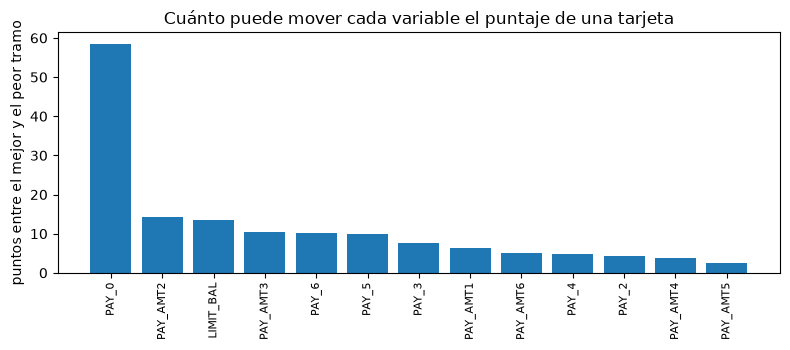

In [9]:
# Calcular la amplitud de los puntos de cada variable desde la tabla versionada y dibujarla
spread = {}
for name in card["features"]:
    pts = [r["points_raw"] for r in table if r["feature"] == name and r["count"] > 0]
    spread[name] = max(pts) - min(pts)
order = sorted(spread, key=lambda n: -spread[n])
for name in order:
    print(f"{name:10s} amplitud de puntos {spread[name]:6.1f}   beta {card['coefficients'][name]:8.4f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(order)), [spread[n] for n in order])
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_ylabel("puntos entre el mejor y el peor tramo")
ax.set_title("Cuánto puede mover cada variable el puntaje de una tarjeta")
fig.tight_layout()
plt.show()


### Paso 7: la tarjeta de puntaje ajustada frente a una línea base de una variable

Un ajuste vale su complejidad solo si supera algo más simple. El escalón P0 de la escalera es una tarjeta de puntaje de una variable solo con `PAY_0` (la misma maquinaria de agrupación, una variable). Las pruebas del motor comparan ambas sobre las 9.000 tarjetas reservadas: el AUC y la distancia de Kolmogorov-Smirnov (la mayor brecha entre las distribuciones de puntaje de incumplidos y no incumplidos), y la prueba de DeLong de la diferencia de AUC para dos modelos puntuados sobre las mismas tarjetas (DeLong, DeLong y Clarke-Pearson, 1988). Los 9.000 puntajes no están en el repositorio, solo las filas versionadas, así que la siguiente celda lee esas filas. Luego llama al motor sobre la muestra de 50 tarjetas para mostrar las mismas dos funciones en acción.

In [10]:
# Leer las filas versionadas del escalón P0 (una variable) y P1 (la tarjeta de puntaje) sobre las 9.000 tarjetas reservadas
def committed_row(test_id, model_id):
    return next(t for t in holdout["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == "portfolio")


print(f"{'':14s} {'AUC':>8s} {'KS':>8s}")
for model_id in ("P0-single", "P1-scorecard"):
    print(f"{model_id:14s} {committed_row('disc.auc', model_id)['metric']:8.4f} {committed_row('disc.ks', model_id)['metric']:8.4f}")
delong = committed_row("disc.delong", "P0-single")
print("DeLong: diferencia de AUC", round(delong["extras"]["difference"], 4), "| z", round(delong["statistic"], 2), "| p", format(delong["p_value"], ".3g"), "|", delong["light"])
print("versionado por riskvalidation", holdout["provenance"]["riskvalidation_version"])


                    AUC       KS
P0-single        0.6917   0.3599
P1-scorecard     0.7587   0.3973
DeLong: diferencia de AUC -0.067 | z -13.35 | p 1.26e-40 | red
versionado por riskvalidation 0.4.3


Las mismas dos funciones del motor sobre la muestra de 50 tarjetas: el AUC y la distancia KS de la PD de la tarjeta de puntaje, y el AUC del puntaje entero solo (se cambia el signo porque un puntaje más alto significa un riesgo menor).

In [11]:
# Las mismas dos funciones del motor sobre la muestra de 50 tarjetas, con la PD de la tarjeta de puntaje
from riskvalidation.validation import disc_auc, disc_ks

policy = rv.default_policy()
pd_card = np.array(sample["scorecard_pd"])
auc = disc_auc(pd_card, y, policy=policy, model_id="P1-scorecard")
ks = disc_ks(pd_card, y, policy=policy, model_id="P1-scorecard")
print("AUC:", round(auc.metric, 4), "| KS:", round(ks.metric, 4), "| tarjetas:", auc.n, "| incumplimientos:", auc.n_events)
print("el mismo ordenamiento solo con el puntaje entero:", round(disc_auc(-score_rebuilt.astype(float), y, policy=policy, model_id="P1-scorecard").metric, 4))


AUC: 0.7752 | KS: 0.5048 | tarjetas: 50 | incumplimientos: 15
el mismo ordenamiento solo con el puntaje entero: 0.7781


### Paso 8: qué requiere un reajuste

Todo lo anterior es el ajuste leído de vuelta. Para reajustarlo, el pipeline necesita el archivo crudo y las librerías que el entorno de los cuadernos no trae (`optbinning==1.0.0`, `statsmodels==0.15.0`, `scikit-learn==1.9.1` y sus dependencias, fijadas en `data-pipeline/requirements.txt`). La ruta documentada, de `docs/guides/01_fetch-and-bake.md`, es un cálculo en caja de arena que escribe fuera del repositorio y deja `data/` intacto:

```bash
python data-pipeline/fetch.py uci-taiwan
python data-pipeline/run.py C01 --output <una carpeta temporal>
```

El cálculo canónico de C01 toma unos doce minutos; ajustar solo la tarjeta de puntaje toma segundos. Un segundo cálculo desde el mismo archivo y la misma semilla reproduce los artefactos versionados byte por byte (el cálculo es una función pura de sus entradas y de la semilla 42). La invarianza del ajuste frente a todo lo que está fuera del tramo de entrenamiento la verifica `tests/test_leakage.py`, que el cuaderno 07 muestra.

## Resultados

- **La división es estratificada y los tramos están separados por propósito.** Los tres tramos comparten una tasa de incumplimiento hasta el cuarto decimal, 22,1%, de modo que la muestra reservada es una muestra justa de la población sobre la que se ajustó la tarjeta de puntaje. Nada en el artefacto versionado deja que la muestra reservada se filtre al ajuste: los conteos de cada una de las 13 variables suman las 16.800 tarjetas de entrenamiento.
- **Los tramos aprendidos respetan sus restricciones.** Cada tramo tiene al menos el 5% de las tarjetas de entrenamiento, y la tasa de incumplimiento se mueve en la dirección declarada a lo largo de los tramos de las 13 variables. `PAY_0` tiene cuatro tramos y las variables de estado de pago de meses anteriores solo dos o tres; los montos de pago tienen de seis a ocho.
- **La tabla de puntos reproduce los puntajes exactamente.** Solo desde las entradas crudas de las 50 tarjetas y los puntos de corte, las 650 celdas de puntos y los 50 puntajes coinciden con lo que guardó el pipeline. Esa es la propiedad que hace auditable a una tarjeta de puntaje: no hace falta un objeto de modelo para explicar un puntaje.
- **Qué pesa el modelo.** La amplitud de puntos es mayor para el estado de pago del último mes (`PAY_0`, cerca de 58 puntos entre su mejor y su peor tramo) y luego para el monto pagado en agosto (`PAY_AMT2`, 14 puntos), el límite de crédito (13 puntos) y las otras variables de pago. Los montos de cuenta no aparecen: se descartaron por valor de información en el cuaderno 01.
- **El ajuste supera a la línea base.** Frente a la tarjeta de puntaje de una variable, la tarjeta completa sube el AUC de 0,692 a 0,759 y el KS de 0,360 a 0,397 sobre las 9.000 tarjetas reservadas, y la prueba de DeLong rechaza AUC iguales (p cerca de 1e-40). La diferencia de 0,067 puntos de AUC es el valor de las otras 12 variables.

Lo que este cuaderno no muestra: los errores estándar y los valores p del paso logístico. El artefacto versionado contiene los coeficientes y los signos, no la tabla estadística del ajuste, y `statsmodels` no está en el entorno de los cuadernos; la verificación de signos (todos los coeficientes negativos) es el rastro visible de ese paso. No reajusta, y no muestra la tarjeta de puntaje fuera del tiempo: C01 es una sola foto de 2005, un límite que el cuaderno 07 enuncia como hallazgo.

## Resumen

- El ajuste es a prueba de fuga por diseño: una división estratificada con semilla fija, tramos y coeficientes aprendidos solo con las 16.800 tarjetas de entrenamiento, un tramo de calibración separado para los retadores y una muestra reservada bloqueada.
- Los tramos aprendidos obedecen sus restricciones, lo que se puede verificar sobre los conteos versionados: tasa de incumplimiento monótona, al menos el 5% de las tarjetas por tramo.
- Una tarjeta de puntaje es auditable: desde los valores crudos y los puntos de corte versionados, la tabla de puntos reproduce cada puntaje exactamente, sin objeto de modelo.
- La amplitud de puntos por variable muestra qué pesa la tarjeta de puntaje; la tarjeta ajustada supera a la línea base de una variable sobre las tarjetas reservadas, con las pruebas de AUC, KS y DeLong del motor.

**Qué probar después.** Elige otra variable en el Paso 3 y lee sus tramos y sus puntos; luego continúa con el cuaderno 03, que corre la batería de validación sobre toda la escalera de modelos.

## Referencias

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation. https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring, 2.ª ed., Wiley. https://doi.org/10.1002/9781119282396
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- Este repositorio: `docs/guides/01_fetch-and-bake.md`, `docs/design/SDD.md` (la división a prueba de fuga de cada caso) y `data-pipeline/pipeline/model/scorecard.py` del pipeline.